# Identifying LLM Authors: CNN vs. LSTM
Solo midterm project

**RQ1:** Can a CNN/LSTM identify the generator from its response?

**RQ2:** How do prompt-only, response-only, and prompt+response inputs compare?

Source: https://huggingface.co/datasets/openbmb/UltraFeedback (MIT dataset card).

Reference paper: https://arxiv.org/abs/2310.01377.


In [2]:
%pip -q install datasets scikit-learn pandas matplotlib tqdm

In [3]:
import copy, hashlib, json, random, re, time, zipfile
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from tqdm.auto import tqdm
SEED=42
def seed_everything():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_everything()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT=Path('midterm_results'); OUT.mkdir(exist_ok=True)
MODELS=['gpt-4','llama-2-13b-chat','falcon-40b-instruct']
PER_CLASS=1000
EPOCHS=8; PATIENCE=2; BATCH_SIZE=32; LR=0.001
MAX_VOCAB=15000; MAX_LEN=256; EMBED_DIM=64; HIDDEN=64
print('Device:',DEVICE)


Device: cuda


## 1. Collect and inspect real examples



In [4]:
stream=load_dataset('openbmb/UltraFeedback', split='train', streaming=True)
rng=random.Random(SEED); pools={m:[] for m in MODELS}; seen=Counter(); scanned=0
for row in tqdm(stream, desc='Scanning original dataset'):
    scanned+=1
    prompt=row.get('instruction','')
    if not isinstance(prompt,str) or not prompt.strip(): continue
    for c in row.get('completions',[]):
        model=c.get('model'); response=c.get('response','')
        if model not in pools or not isinstance(response,str) or not response.strip(): continue
        item={'LLM_name':model,'LLM_Input':prompt,'LLM_Output':response,
              'source':row.get('source',''),'principle':c.get('principle',''),
              'system_prompt':c.get('custom_system_prompt','')}
        seen[model]+=1
        if len(pools[model])<PER_CLASS: pools[model].append(item)
        else:
            j=rng.randrange(seen[model])
            if j<PER_CLASS: pools[model][j]=item
print('Scanned prompts:',scanned,'Eligible counts:',dict(seen))
assert all(pools[m] for m in MODELS), 'A requested model is missing. Inspect dataset labels.'
df=pd.DataFrame([r for m in MODELS for r in pools[m]])
df=df.drop_duplicates(['LLM_name','LLM_Input','LLM_Output'])
df=df.drop_duplicates('LLM_Output',keep=False)
n=min(df.LLM_name.value_counts())
assert n>=100, 'Insufficient examples; investigate data before training.'
df=pd.concat([g.sample(n=n,random_state=SEED) for _,g in df.groupby('LLM_name')],ignore_index=True)
def prompt_key(s): return hashlib.sha256(' '.join(s.lower().split()).encode()).hexdigest()
df['prompt_group']=df.LLM_Input.map(prompt_key)
df['label']=df.LLM_name.map({m:i for i,m in enumerate(MODELS)})
display(df.LLM_name.value_counts(),pd.crosstab(df.source,df.LLM_name))
display(df[['LLM_name','LLM_Input','LLM_Output']].sample(6,random_state=SEED))
print('Inspect examples for personal information, explicit model self-identification, and quality before proceeding.')


README.md:   0%|          | 0.00/15.4k [00:00<?, ?B/s]

Scanning original dataset: 0it [00:00, ?it/s]

Scanned prompts: 63967 Eligible counts: {'gpt-4': 16518, 'llama-2-13b-chat': 16632, 'falcon-40b-instruct': 16487}


,count
LLM_name,
falcon-40b-instruct,977
gpt-4,977
llama-2-13b-chat,977


LLM_name,falcon-40b-instruct,gpt-4,llama-2-13b-chat
source,,,
evol_instruct,125,157,152
false_qa,40,37,34
flan_v2_cot,55,44,41
flan_v2_flan2021,8,16,10
flan_v2_niv2,224,221,236
flan_v2_p3,30,31,30
sharegpt,337,321,325
truthful_qa,14,17,12
ultrachat,144,133,137


,LLM_name,LLM_Input,LLM_Output
1357,gpt-4,Tell me a story about a group of animals who e...,"Once upon a time, deep in the heart of the Gre..."
2367,llama-2-13b-chat,Rotate the following matrix by 45 degrees coun...,"Sure, I'd be happy to help! To rotate the matr..."
2822,llama-2-13b-chat,"Given the task definition and input, reply wit...",Hello! I'd be happy to help you with this task...
2126,llama-2-13b-chat,Can you write me some Javascript code that mak...,Certainly! Here is some JavaScript code that m...
1544,gpt-4,Where do ibexes' wings grow?,Ibexes do not have wings. They are a type of w...
2415,llama-2-13b-chat,Write a 12-line poem in free verse that captur...,"Sure, here's a 12-line poem in free verse that..."


Inspect examples for personal information, explicit model self-identification, and quality before proceeding.


## 2. Split by prompt: roughly 70% train, 15% validation, 15% test



In [5]:
splitter=GroupShuffleSplit(n_splits=1,test_size=0.30,random_state=SEED)
train_idx,hold_idx=next(splitter.split(df,groups=df.prompt_group))
hold=df.iloc[hold_idx]
splitter2=GroupShuffleSplit(n_splits=1,test_size=0.50,random_state=SEED+1)
val_rel,test_rel=next(splitter2.split(hold,groups=hold.prompt_group))
df['split']='train'
df.loc[hold.index[val_rel],'split']='validation'; df.loc[hold.index[test_rel],'split']='test'
parts={s:df[df.split==s].reset_index(drop=True) for s in ['train','validation','test']}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert set(parts[a].prompt_group).isdisjoint(parts[b].prompt_group)
for s,p in parts.items(): assert set(p.label)==set(range(3)), f'Missing class in {s}'
display(pd.crosstab(df.split,df.LLM_name))
df.to_csv(OUT/'dataset_with_splits.csv',index=False)
manifest={'dataset':'openbmb/UltraFeedback','url':'https://huggingface.co/datasets/openbmb/UltraFeedback',
          'models':MODELS,'seed':SEED,'eligible_counts':dict(seen),'scanned_prompts':scanned,
          'rows_after_cleaning':len(df),'input_definition':'user instruction only',
          'settings':{'epochs':EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,'lr':LR,
                      'max_vocab':MAX_VOCAB,'max_length':MAX_LEN,'embedding_dim':EMBED_DIM,'hidden':HIDDEN}}
(OUT/'data_and_settings.json').write_text(json.dumps(manifest,indent=2))


LLM_name,falcon-40b-instruct,gpt-4,llama-2-13b-chat
split,,,
test,166,142,131
train,657,681,717
validation,154,154,129


605

## 3. Tokenization



In [6]:
def tokens(s): return re.findall(r"\w+|[^\w\s]",s.lower())
def selected_tokens(row,mode):
    if mode=='prompt': return tokens(row.LLM_Input)[:MAX_LEN]
    if mode=='response': return tokens(row.LLM_Output)[:MAX_LEN]
    p=tokens(row.LLM_Input)[:MAX_LEN//2]
    return p+['<sep>']+tokens(row.LLM_Output)[:MAX_LEN-len(p)-1]
def prepare(mode):
    counts=Counter(t for r in parts['train'].itertuples() for t in selected_tokens(r,mode) if t!='<sep>')
    vocab={'<pad>':0,'<unk>':1,'<sep>':2}
    vocab.update({t:i+3 for i,(t,_) in enumerate(counts.most_common(MAX_VOCAB-3))})
    loaders={}
    for s,p in parts.items():
        X=np.zeros((len(p),MAX_LEN),dtype=np.int64); lengths=[]
        for i,r in enumerate(p.itertuples()):
            ts=selected_tokens(r,mode) or ['<unk>']; ids=[vocab.get(t,1) for t in ts]
            X[i,:len(ids)]=ids; lengths.append(len(ids))
        ds=TensorDataset(torch.tensor(X),torch.tensor(lengths),torch.tensor(p.label.to_numpy(),dtype=torch.long))
        loaders[s]=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=(s=='train'))
    (OUT/f'{mode}_vocabulary.json').write_text(json.dumps(vocab))
    return vocab,loaders


## 4. Required architectures



In [7]:
class TextCNN(nn.Module):
    def __init__(self,size):
        super().__init__(); self.embedding=nn.Embedding(size,EMBED_DIM,padding_idx=0)
        self.convs=nn.ModuleList([nn.Conv1d(EMBED_DIM,HIDDEN,k) for k in [3,4,5]])
        self.dropout=nn.Dropout(0.3); self.fc=nn.Linear(3*HIDDEN,3)
    def forward(self,x,lengths):
        z=self.embedding(x).transpose(1,2); pooled=[]
        for conv in self.convs:
            h=torch.relu(conv(z)); positions=torch.arange(h.size(2),device=x.device)[None,:]
            valid=positions<lengths.to(x.device)[:,None]
            h=h.masked_fill(~valid[:,None,:],float('-inf'))
            pooled.append(h.amax(dim=2))
        return self.fc(self.dropout(torch.cat(pooled,dim=1)))
class TextLSTM(nn.Module):
    def __init__(self,size):
        super().__init__(); self.embedding=nn.Embedding(size,EMBED_DIM,padding_idx=0)
        self.lstm=nn.LSTM(EMBED_DIM,HIDDEN,batch_first=True)
        self.dropout=nn.Dropout(0.3); self.fc=nn.Linear(HIDDEN,3)
    def forward(self,x,lengths):
        packed=pack_padded_sequence(self.embedding(x),lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,(h,_)=self.lstm(packed)
        return self.fc(self.dropout(h[-1]))
@torch.no_grad()
def evaluate(model,loader):
    model.eval(); truth=[]; pred=[]; loss_sum=0
    for x,lengths,y in loader:
        logits=model(x.to(DEVICE),lengths); loss_sum+=nn.functional.cross_entropy(logits,y.to(DEVICE),reduction='sum').item()
        truth.extend(y.tolist()); pred.extend(logits.argmax(1).cpu().tolist())
    return loss_sum/len(truth),np.array(truth),np.array(pred)


## 5. Run all six experiments



In [8]:
results=[]
for mode in ['prompt','response','combined']:
    seed_everything(); vocab,loaders=prepare(mode)
    for name,cls in [('CNN',TextCNN),('LSTM',TextLSTM)]:
        seed_everything(); model=cls(len(vocab)).to(DEVICE)
        optimizer=torch.optim.Adam(model.parameters(),lr=LR)
        best=-1; best_state=None; stale=0; history=[]; start=time.time()
        for epoch in range(1,EPOCHS+1):
            model.train(); total=0
            for x,lengths,y in loaders['train']:
                optimizer.zero_grad(); logits=model(x.to(DEVICE),lengths)
                loss=nn.functional.cross_entropy(logits,y.to(DEVICE)); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
                total+=loss.item()*len(y)
            vl,yt,yp=evaluate(model,loaders['validation']); vf=f1_score(yt,yp,average='macro',zero_division=0)
            history.append({'epoch':epoch,'train_loss':total/len(parts['train']),'validation_loss':vl,'validation_macro_f1':vf})
            print(f'{name}/{mode} epoch {epoch}: val macro F1={vf:.3f}')
            if vf>best:
                best=vf; best_state=copy.deepcopy(model.state_dict()); best_epoch=epoch; stale=0
            else: stale+=1
            if stale>=PATIENCE: break
        model.load_state_dict(best_state); _,yt,yp=evaluate(model,loaders['test'])
        tag=f'{name}_{mode}'
        torch.save({'state_dict':{k:v.cpu() for k,v in best_state.items()},'model':name,'mode':mode,
                    'vocab_size':len(vocab),'settings':manifest['settings'],'classes':MODELS},OUT/f'{tag}.pt')
        pd.DataFrame(history).to_csv(OUT/f'{tag}_history.csv',index=False)
        (OUT/f'{tag}_classification_report.json').write_text(json.dumps(classification_report(yt,yp,labels=[0,1,2],target_names=MODELS,output_dict=True,zero_division=0),indent=2))
        pd.DataFrame({'prompt_group':parts['test'].prompt_group,'true_label':yt,'predicted_label':yp}).to_csv(OUT/f'{tag}_predictions.csv',index=False)
        fig,ax=plt.subplots(figsize=(7,5)); ConfusionMatrixDisplay.from_predictions(yt,yp,labels=[0,1,2],display_labels=MODELS,ax=ax,xticks_rotation=25)
        ax.set_title(tag); fig.tight_layout(); fig.savefig(OUT/f'{tag}_confusion.png',dpi=160); plt.close(fig)
        results.append({'model':name,'input':mode,'test_accuracy':accuracy_score(yt,yp),
                        'test_macro_f1':f1_score(yt,yp,average='macro',zero_division=0),
                        'best_validation_macro_f1':best,'best_epoch':best_epoch,'seconds':time.time()-start})
        pd.DataFrame(results).to_csv(OUT/'results.csv',index=False)
        print('Saved:',tag); del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
display(pd.DataFrame(results))


CNN/prompt epoch 1: val macro F1=0.228
CNN/prompt epoch 2: val macro F1=0.236
CNN/prompt epoch 3: val macro F1=0.238
CNN/prompt epoch 4: val macro F1=0.237
CNN/prompt epoch 5: val macro F1=0.231
Saved: CNN_prompt
LSTM/prompt epoch 1: val macro F1=0.265
LSTM/prompt epoch 2: val macro F1=0.209
LSTM/prompt epoch 3: val macro F1=0.207
Saved: LSTM_prompt
CNN/response epoch 1: val macro F1=0.736
CNN/response epoch 2: val macro F1=0.693
CNN/response epoch 3: val macro F1=0.694
Saved: CNN_response
LSTM/response epoch 1: val macro F1=0.453
LSTM/response epoch 2: val macro F1=0.525
LSTM/response epoch 3: val macro F1=0.532
LSTM/response epoch 4: val macro F1=0.525
LSTM/response epoch 5: val macro F1=0.561
LSTM/response epoch 6: val macro F1=0.485
LSTM/response epoch 7: val macro F1=0.523
Saved: LSTM_response
CNN/combined epoch 1: val macro F1=0.707
CNN/combined epoch 2: val macro F1=0.709
CNN/combined epoch 3: val macro F1=0.696
CNN/combined epoch 4: val macro F1=0.672
Saved: CNN_combined
LSTM/c

,model,input,test_accuracy,test_macro_f1,best_validation_macro_f1,best_epoch,seconds
0,CNN,prompt,0.325740,0.238211,0.238375,3,4.776353
1,LSTM,prompt,0.302961,0.266483,0.264599,1,3.141986
2,CNN,response,0.708428,0.717379,0.736499,1,1.148589
3,LSTM,response,0.544419,0.541520,0.561009,5,7.089366
4,CNN,combined,0.649203,0.663060,0.709235,2,1.867460
5,LSTM,combined,0.546697,0.538359,0.586933,5,7.453186


## 6. Compare results and prepare the required report



Majority baseline accuracy: 0.2984054669703872
Majority baseline macro F1: 0.15321637426900583


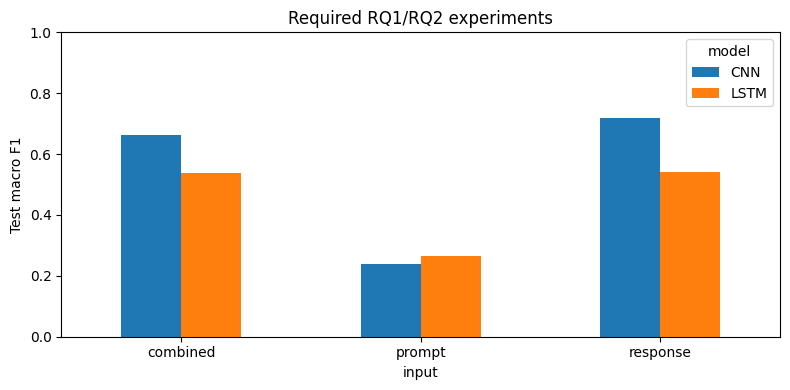

In [9]:
majority=int(parts['train'].label.mode().iloc[0]); y=parts['test'].label.to_numpy()
print('Majority baseline accuracy:',accuracy_score(y,np.full(len(y),majority)))
print('Majority baseline macro F1:',f1_score(y,np.full(len(y),majority),average='macro',zero_division=0))
r=pd.DataFrame(results)
fig,ax=plt.subplots(figsize=(8,4)); r.pivot(index='input',columns='model',values='test_macro_f1').plot.bar(ax=ax)
ax.set_ylim(0,1); ax.set_ylabel('Test macro F1'); ax.set_title('Required RQ1/RQ2 experiments'); plt.xticks(rotation=0)
fig.tight_layout(); fig.savefig(OUT/'comparison.png',dpi=180); plt.show()


In [10]:
with zipfile.ZipFile('midterm_results.zip','w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p,p.as_posix())
try:
    from google.colab import files
    files.download('midterm_results.zip')
except ImportError:
    print('Results saved to midterm_results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>